# Investigation: what drives the results?
Notebooks 3–5 answered the project's questions. This one digs into **why**, one stage at a time:

1. **Training**: are the agents learning, and what do they end up holding?
2. **Choosing an agent**: is the ensemble's choice better than guessing?
3. **How sure are we?** Seed noise vs. market noise, with confidence intervals.
4. **Robustness**: a 5-year training window, and trading fees.
5. **The crash rule**: when it costs money, and gentler alternatives.
6. **FTA with 20 seeds.**

**Extra runs used here** (from `train.py`, `curves.py` and `backtest.py`):
- **20 seeds** (instead of 5) for baseline and FTA on the 40 quarters from 2016 to 2025. Seeds 5–19 start in 2016 with $1M in cash; seeds 0–4 carry their portfolio over from 2000, which barely matters (checked: 99.5% daily correlation).
- A **`rolling`** variant: the baseline trained only on the last 5 years.
- **Learning curves**: 5 folds × 3 seeds, trained up to 3× the base training steps.
- A **sweep** of crash rules, turbulence thresholds and fees for the ensemble.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import levene, spearmanr, wilcoxon
from backtest import STRATEGIES, load_folds, metrics, pretty, sharpe, summary

bt = pd.read_parquet('results/backtest.parquet')
sweep = pd.read_parquet('results/sweep.parquet')
baselines = pd.read_parquet('results/baselines.parquet')
val = pd.read_csv('results/validation.csv')
curves = pd.read_csv('results/curves.csv')
folds = load_folds()
djia = baselines.DJIA

main = bt[(bt.seed < 5) & (bt.variant == 'baseline')]                   # the paper's setup: 101 quarters x 5 seeds
recent = bt[(bt.date >= '2016-01-01') & bt.variant.isin(['baseline', 'fta'])]   # 2016-2025: 20 seeds each


def mean_ret(df, rule, strategy='ensemble'):
    # daily return of a strategy, averaged over the seeds
    return df[(df.strategy == strategy) & (df.rule == rule)].groupby('date').ret.mean()

## 1. Training

### 1a. Learning curves: are the base training steps enough?
Each agent is trained to 3× the base training steps (taken from the authors' code), and every 0.2× we measure its Sharpe ratio on its **training window** (in-sample) and on the **next quarter** (validation, out-of-sample). Dotted lines: the DJIA over the same windows.
- Training Sharpe rising while validation stays flat = the agent fits the past without learning anything that carries forward (overfitting).
- Both flat near the DJIA = the agent isn't learning much beyond holding stocks.

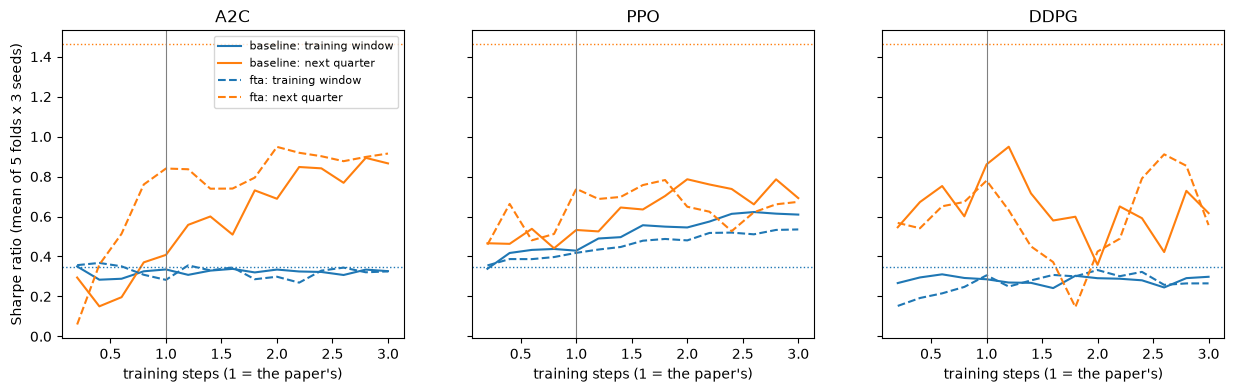

In [2]:
c = curves.assign(x=curves.steps / curves.paper_steps)
c = c.groupby(['agent', 'variant', 'x'])[['train_sharpe', 'val_sharpe']].mean()
used = folds.loc[curves.fold.unique()]
djia_train = np.mean([sharpe(djia.loc[f.train_start:f.val_start]) for f in used.itertuples()])
djia_val = np.mean([sharpe(djia.loc[f.val_start:f.test_start]) for f in used.itertuples()])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, a in zip(axes, ['a2c', 'ppo', 'ddpg']):
    for v, ls in [('baseline', '-'), ('fta', '--')]:
        d = c.loc[(a, v)]
        ax.plot(d.index, d.train_sharpe, ls, color='tab:blue', label=f'{v}: training window')
        ax.plot(d.index, d.val_sharpe, ls, color='tab:orange', label=f'{v}: next quarter')
    ax.axhline(djia_train, color='tab:blue', ls=':', lw=1)
    ax.axhline(djia_val, color='tab:orange', ls=':', lw=1)
    ax.axvline(1, color='gray', lw=0.8)
    ax.set_title(a.upper())
    ax.set_xlabel("training steps (1 = the paper's)")
axes[0].set_ylabel('Sharpe ratio (mean of 5 folds x 3 seeds)')
axes[0].legend(fontsize=8);

### 1b. What do the agents hold?
Average over the 101 test quarters (crash rule `none`, 5 seeds): cash share, number of stocks held (above 0.1% of the portfolio) and turnover (traded value per year, as a multiple of the portfolio).

In [3]:
none = main[main.rule == 'none']
hold = none.groupby('strategy')[['cash', 'held', 'turnover']].mean().loc[STRATEGIES]
hold['turnover'] *= 252
hold.style.format({'cash': '{:.1%}', 'held': '{:.1f}', 'turnover': '{:.1f}x'})

,cash,held,turnover
strategy,,,
ensemble,0.2%,16.6,6.7x
a2c,0.2%,15.9,3.4x
ppo,0.4%,19.1,5.5x
ddpg,0.1%,13.2,6.0x


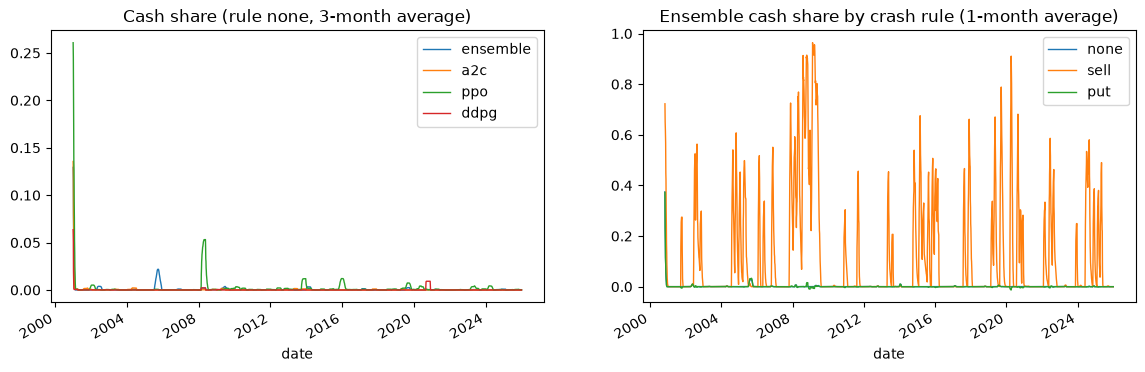

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for s in STRATEGIES:
    none[none.strategy == s].groupby('date').cash.mean().rolling(63).mean().plot(ax=axes[0], label=s, lw=1)
axes[0].set_title('Cash share (rule none, 3-month average)')
axes[0].legend()
for rule in ['none', 'sell', 'put']:
    main[(main.strategy == 'ensemble') & (main.rule == rule)].groupby('date').cash.mean().rolling(21).mean().plot(ax=axes[1], label=rule, lw=1)
axes[1].set_title('Ensemble cash share by crash rule (1-month average)')
axes[1].legend();

### 1c. Simple benchmarks
If the agents don't beat **1/N** (equal weights in the 30 members, rebalanced daily) or a **random agent** (random trades through the same environment), the RL adds nothing. DeMiguel, Garlappi & Uppal (2009) found 1/N hard to beat for most optimised portfolios.

In [5]:
cols = ['Annual return', 'Annual volatility', 'Sharpe (rf = 0)', 'Max drawdown']
pretty(summary(none, baselines)[cols])

,Annual return,Annual volatility,Sharpe (rf = 0),Max drawdown
a2c,8.5%,20.7%,0.50,-55.3%
ddpg,7.4%,20.4%,0.45,-57.4%
ensemble,8.2%,19.7%,0.50,-56.5%
ppo,9.4%,20.0%,0.55,-57.9%
DJIA,8.7%,18.3%,0.55,-51.8%
Min-variance,7.4%,14.4%,0.57,-31.5%
1/N,8.9%,19.5%,0.53,-60.0%
Random agent,5.2%,18.3%,0.37,-57.2%


## 2. Choosing an agent

### 2a. Does a good validation quarter predict a good test quarter?
The ensemble picks the agent with the best Sharpe ratio on the last 3 months. That only helps if a high validation Sharpe goes with a high Sharpe in the next quarter.

**Theory (Lo, 2002):** the standard error of an annualised Sharpe ratio is about √((1 + SR²/2) / years). For one quarter that's **±2.1**: much larger than the real differences between the agents.

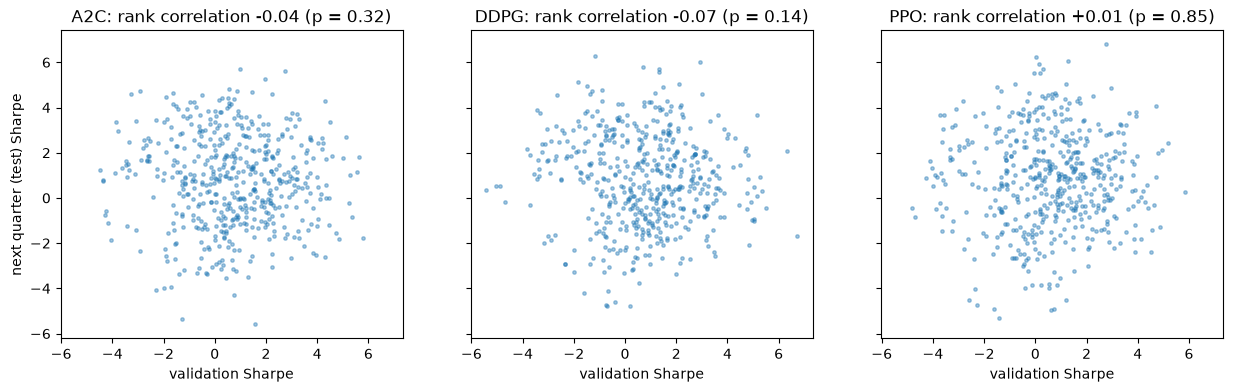

In [6]:
sell = main[main.rule == 'sell']
test_q = sell[sell.strategy != 'ensemble'].groupby(['seed', 'fold', 'strategy']).ret.apply(sharpe)
v = val[(val.variant == 'baseline') & (val.seed < 5)].rename(columns={'agent': 'strategy'})
vt = v.set_index(['seed', 'fold', 'strategy']).val_sharpe.to_frame().join(test_q.rename('test_sharpe')).dropna()

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, (a, g) in zip(axes, vt.groupby('strategy')):
    rho = spearmanr(g.val_sharpe, g.test_sharpe)
    ax.scatter(g.val_sharpe, g.test_sharpe, s=6, alpha=0.4)
    ax.set_title(f'{a.upper()}: rank correlation {rho.correlation:+.2f} (p = {rho.pvalue:.2f})')
    ax.set_xlabel('validation Sharpe')
axes[0].set_ylabel('next quarter (test) Sharpe');

In [7]:
quarter = sell[sell.strategy != 'ensemble'].groupby(['seed', 'fold', 'strategy']).ret.apply(lambda r: (1 + r).prod() - 1).unstack()
pick = sell[sell.strategy == 'ensemble'].groupby(['seed', 'fold']).agent.first()
print(f'The picked agent is the best of the 3 in its test quarter {(quarter.idxmax(axis=1) == pick).mean():.0%} of the time '
      f'(random guessing: 33%)')

The picked agent is the best of the 3 in its test quarter 35% of the time (random guessing: 33%)


### 2b. The ensemble against other ways of choosing
- **Random pick**: a random agent each quarter (the floor).
- **Equal mix**: a third of the money with each agent.
- **Always PPO**: the agent that did best on average.
- **Oracle**: the agent that turned out best that quarter, known in hindsight (the ceiling, not achievable).

Each choice uses that agent's own quarterly returns, so this is a close approximation, not a rerun. Bailey & López de Prado's *Deflated Sharpe Ratio* explains the trap: picking the best of several noisy results looks better than it is.

In [8]:
def selection_table(rule):
    d = main[main.rule == rule]
    agents = d[d.strategy != 'ensemble'].pivot_table(index=['seed', 'fold', 'date'], columns='strategy', values='ret')
    quarter = (1 + agents).groupby(level=['seed', 'fold']).prod() - 1
    rng = np.random.default_rng(0)
    choice = {'Oracle (hindsight)': quarter.idxmax(axis=1),
              'Random pick': pd.Series(rng.choice(agents.columns, len(quarter)), index=quarter.index)}
    series = {'Ensemble (validation Sharpe)': d[d.strategy == 'ensemble'].set_index(['seed', 'fold', 'date']).ret,
              'Equal mix': agents.mean(axis=1), 'Always PPO': agents.ppo}
    for name, ch in choice.items():
        col = agents.columns.get_indexer(ch.reindex(agents.index.droplevel('date')).values)
        series[name] = pd.Series(agents.values[np.arange(len(agents)), col], index=agents.index)
    rows = {}
    for name, s in series.items():
        per_seed = [metrics(x.droplevel(['seed', 'fold']), baselines.rf) for _, x in s.groupby(level='seed')]
        rows[name] = pd.DataFrame(per_seed).mean()
    return pd.DataFrame(rows).T[cols]

pretty(pd.concat({'rule none': selection_table('none'), 'rule sell (paper)': selection_table('sell')}))

### 2c. Do the seeds pick the same agent?
Which agent the ensemble picks in each quarter from 2016, for all 20 seeds.

On average 56% of the seeds pick the same agent (picking at random would give about 44%)


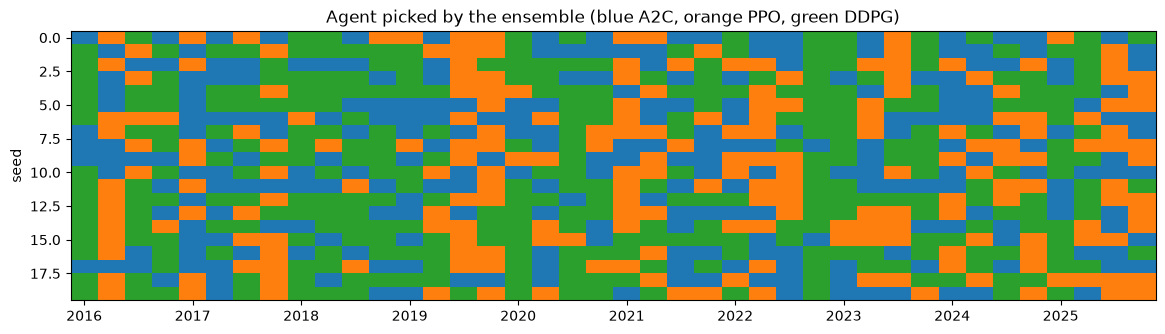

In [9]:
picks = recent[(recent.variant == 'baseline') & (recent.strategy == 'ensemble') & (recent.rule == 'none')]
picks = picks.groupby(['fold', 'seed']).agent.first().unstack()
codes = picks.replace({'a2c': 0, 'ppo': 1, 'ddpg': 2}).astype(float)
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.imshow(codes.T, aspect='auto', cmap=plt.matplotlib.colors.ListedColormap(['tab:blue', 'tab:orange', 'tab:green']))
ax.set_xticks(range(0, len(picks), 4), folds.test_start.loc[picks.index[::4]].dt.year)
ax.set_ylabel('seed')
ax.set_title('Agent picked by the ensemble (blue A2C, orange PPO, green DDPG)')
agree = picks.apply(lambda r: r.value_counts().iloc[0] / r.count(), axis=1)
print(f'On average {agree.mean():.0%} of the seeds pick the same agent (picking at random would give about 44%)')

## 3. How sure are we?

Two kinds of noise sit in every number here:
- **Seed noise**: retrain with another seed and you get a different agent. More seeds average it away.
- **Market noise**: all seeds trade the *same* 2000–2025 history. A different but equally likely history would give a different Sharpe ratio. More seeds can't fix this; only more years can.

### 3a. Sharpe ratio of every seed, 2016–2025 (20 seeds)
Agarwal et al. (2021) recommend reporting the spread and the **interquartile mean** (IQM, the mean of the middle 50% of runs) instead of a single mean.

count         mean            iqm            std            min  \
variant  baseline fta baseline   fta baseline   fta baseline   fta baseline   
strategy                                                                      
ensemble       20  20     0.73  0.73     0.73  0.74     0.08  0.07     0.58   
a2c            20  20     0.69  0.78     0.72  0.76     0.18  0.13     0.37   
ppo            20  20     0.75  0.70     0.74  0.69     0.11  0.10     0.57   
ddpg           20  20     0.69  0.65     0.70  0.65     0.12  0.15     0.44   

                    max        
variant    fta baseline   fta  
strategy                       
ensemble  0.62     0.86  0.85  
a2c       0.57     0.96  1.04  
ppo       0.57     1.00  0.93  
ddpg      0.39     0.87  0.97

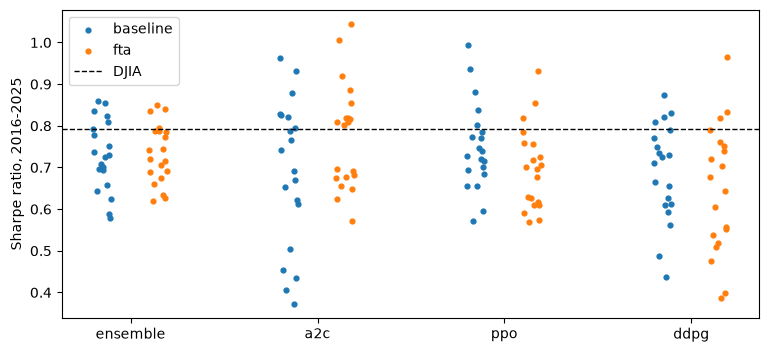

In [10]:
r20 = recent[recent.rule == 'none']
sh20 = r20.groupby(['variant', 'strategy', 'seed']).ret.apply(sharpe)

def iqm(x):
    x = np.sort(x)
    return x[len(x) // 4: len(x) - len(x) // 4].mean()

table = sh20.groupby(['strategy', 'variant']).agg(['count', 'mean', iqm, 'std', 'min', 'max']).unstack('variant')
display(table.loc[STRATEGIES].round(2))

fig, ax = plt.subplots(figsize=(9, 4))
for i, s in enumerate(STRATEGIES):
    for j, v in enumerate(['baseline', 'fta']):
        y = sh20.loc[(v, s)]
        ax.scatter(i + (j - 0.5) * 0.3 + np.random.default_rng(0).uniform(-0.05, 0.05, len(y)), y, s=12,
                   color=['tab:blue', 'tab:orange'][j], label=v if i == 0 else None)
ax.axhline(sharpe(djia.loc['2016':]), color='black', ls='--', lw=1, label='DJIA')
ax.set_xticks(range(len(STRATEGIES)), STRATEGIES)
ax.set_ylabel('Sharpe ratio, 2016-2025')
ax.legend();

### 3b. Seed noise vs. market noise
**Seed noise of the average:** how much the average Sharpe over *n* seeds would change with another set of *n* seeds (resampling the 20 seeds). It falls like 1/√n.

**Market noise:** a block bootstrap of the seed-averaged daily returns (blocks of 21 days keep volatility clusters together), i.e. the Sharpe ratios we'd see on many alternative market histories.

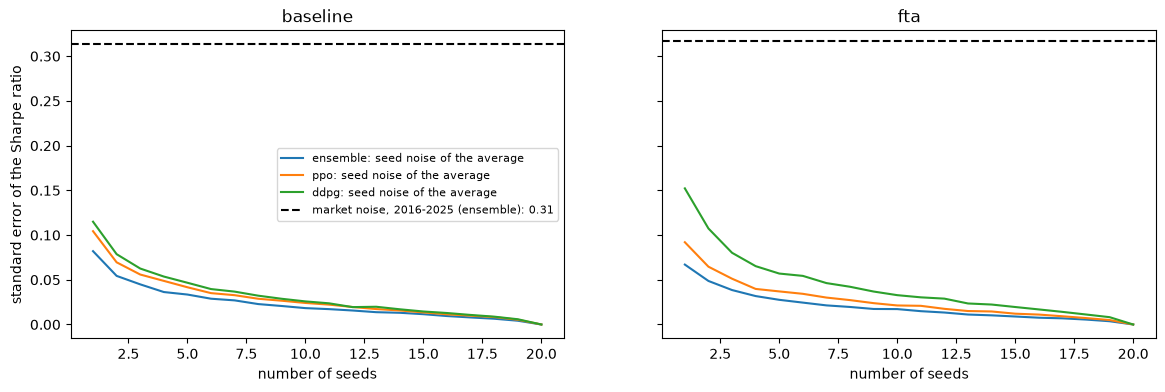

In [11]:
def boot_idx(T, n=2000, block=21, seed=0):
    # moving-block bootstrap: n resampled histories, as row indices
    rng = np.random.default_rng(seed)
    starts = rng.integers(0, T - block, (n, T // block + 1))
    return (starts[:, :, None] + np.arange(block)).reshape(n, -1)[:, :T]

def boot_sharpe(r, idx):
    x = np.asarray(r)[idx]
    return x.mean(1) / x.std(1) * np.sqrt(252)

rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, v in zip(axes, ['baseline', 'fta']):
    for s in ['ensemble', 'ppo', 'ddpg']:
        x = sh20.loc[(v, s)].values
        ns = range(1, len(x) + 1)
        sd = [np.std([rng.choice(x, n, replace=False).mean() for _ in range(500)]) for n in ns]
        ax.plot(ns, sd, label=f'{s}: seed noise of the average')
    r = mean_ret(r20[r20.variant == v], 'none')
    market = boot_sharpe(r, boot_idx(len(r))).std()
    ax.axhline(market, color='black', ls='--', label=f'market noise, 2016-2025 (ensemble): {market:.2f}')
    ax.set_title(v)
    ax.set_xlabel('number of seeds')
axes[0].set_ylabel('standard error of the Sharpe ratio')
axes[0].legend(fontsize=8);

**What this means for "fewer quarters, more seeds":** after about 5 seeds the seed noise of the average is already several times smaller than the market noise. Extra seeds sharpen the *seed* part only, while cutting quarters shortens the history and raises the market noise (it grows like 1/√years). So for the performance questions, years matter more than seeds. Seeds matter most for questions *about* seeds, like FTA's stability (section 6).

### 3c. Confidence intervals, full period
95% block-bootstrap intervals for each Sharpe ratio, and for its difference from the DJIA (same resampled days for both, so the common market moves cancel). An interval that contains 0 means the difference could be luck.

In [12]:
series = {f'ensemble, rule {rule}': mean_ret(main, rule) for rule in ['none', 'sell', 'put']}
series |= {s.upper(): mean_ret(main, 'none', s) for s in ['a2c', 'ppo', 'ddpg']}
series |= {b: baselines[b] for b in ['DJIA', '1/N', 'Min-variance']}
frame = pd.DataFrame(series).dropna()
idx = boot_idx(len(frame))
d_boot = boot_sharpe(frame.DJIA, idx)
rows = {}
for name in frame:
    b = boot_sharpe(frame[name], idx)
    rows[name] = {'Sharpe': sharpe(frame[name]), 'low': np.quantile(b, 0.025), 'high': np.quantile(b, 0.975),
                  'vs DJIA': sharpe(frame[name]) - sharpe(frame.DJIA),
                  'vs DJIA low': np.quantile(b - d_boot, 0.025), 'vs DJIA high': np.quantile(b - d_boot, 0.975)}
pd.DataFrame(rows).T.round(2)

,Sharpe,low,high,vs DJIA,vs DJIA low,vs DJIA high
"ensemble, rule none",0.53,0.18,0.92,-0.02,-0.11,0.06
"ensemble, rule sell",0.45,0.09,0.85,-0.10,-0.28,0.09
"ensemble, rule put",0.50,0.13,0.90,-0.05,-0.24,0.16
A2C,0.53,0.18,0.92,-0.02,-0.10,0.06
PPO,0.57,0.20,0.96,0.02,-0.13,0.16
DDPG,0.50,0.16,0.89,-0.05,-0.16,0.05
DJIA,0.55,0.21,0.93,0.00,0.00,0.00
1/N,0.53,0.20,0.93,-0.01,-0.09,0.05
Min-variance,0.57,0.22,0.96,0.02,-0.18,0.22


### 3d. When does the ensemble gain or lose against the DJIA?

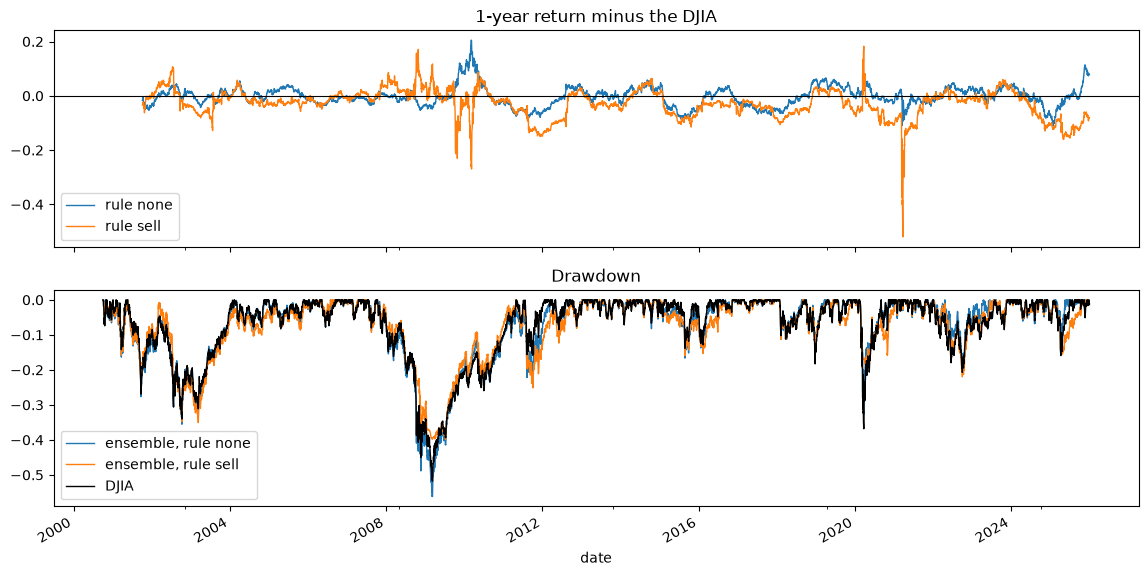

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for rule in ['none', 'sell']:
    r = mean_ret(main, rule)
    excess = (1 + r).rolling(252).apply(np.prod, raw=True) - (1 + djia.reindex(r.index)).rolling(252).apply(np.prod, raw=True)
    excess.plot(ax=axes[0], label=f'rule {rule}', lw=1)
    v = (1 + r).cumprod()
    (v / v.cummax() - 1).plot(ax=axes[1], label=f'ensemble, rule {rule}', lw=1)
v = (1 + djia).cumprod()
(v / v.cummax() - 1).plot(ax=axes[1], label='DJIA', color='black', lw=1)
axes[0].axhline(0, color='black', lw=0.8)
axes[0].set_title('1-year return minus the DJIA')
axes[1].set_title('Drawdown')
axes[0].legend(); axes[1].legend();

## 4. Robustness

### 4a. Is old data the problem? A 5-year training window
`rolling` trains each quarter's agents on the last 5 years only, instead of everything since 2000. Same seeds 0–4, folds and settings. Table: Sharpe ratio, 2000–2025.

In [14]:
roll = bt[(bt.seed < 5) & bt.variant.isin(['baseline', 'rolling'])]
tab = {}
for rule in ['none', 'sell']:
    for v in ['baseline', 'rolling']:
        tab[(f'rule {rule}', v)] = summary(roll[(roll.rule == rule) & (roll.variant == v)], baselines).loc[STRATEGIES, 'Sharpe (rf = 0)']
display(pd.DataFrame(tab).round(2))

q = roll[roll.rule == 'none'].groupby(['variant', 'strategy', 'seed', 'fold']).ret.apply(lambda r: (1 + r).prod() - 1)
q = q.groupby(['variant', 'strategy', 'fold']).mean().unstack('variant')
for s, g in q.groupby('strategy'):
    print(f'{s:9s} rolling beats expanding in {(g['rolling'] > g['baseline']).mean():.0%} of quarters, '
          f'Wilcoxon p = {wilcoxon(g['rolling'], g['baseline']).pvalue:.2f}')

rule none         rule sell        
          baseline rolling  baseline rolling
ensemble      0.50    0.52      0.43    0.46
a2c           0.50    0.50      0.41    0.45
ppo           0.55    0.55      0.52    0.51
ddpg          0.45    0.46      0.41    0.38

a2c       rolling beats expanding in 44% of quarters, Wilcoxon p = 0.44
ddpg      rolling beats expanding in 41% of quarters, Wilcoxon p = 0.62
ensemble  rolling beats expanding in 47% of quarters, Wilcoxon p = 0.81
ppo       rolling beats expanding in 51% of quarters, Wilcoxon p = 0.66


### 4b. Trading fees
The agents were trained with the paper's 0.1% fee; here only the test fee changes (ensemble, rule `none`).

In [15]:
fees = pd.concat([sweep[sweep.rule.str.startswith('none@')], main[(main.strategy == 'ensemble') & (main.rule == 'none')].assign(rule='none@fee0.001')])
fees = summary(fees, baselines, by='rule').drop(baselines.columns.drop('rf'))
fees.index = [f'{float(i.split("fee")[1]):.2%}' for i in fees.index]
pretty(fees.sort_index()[cols])

,Annual return,Annual volatility,Sharpe (rf = 0),Max drawdown
0.00%,8.9%,19.7%,0.53,-56.0%
0.05%,8.6%,19.7%,0.52,-56.2%
0.10%,8.2%,19.7%,0.50,-56.5%
0.20%,7.5%,19.7%,0.46,-56.9%


## 5. The crash rule

### 5a. Where the gap to the DJIA comes from
Total log growth, split into **calm days** and **turbulent periods** (a turbulent day plus the 10 days after it).

,DJIA,none,sell,put
calm days (86%),1.43,1.45,1.37,1.56
turbulent periods (14%),0.67,0.58,0.05,0.11


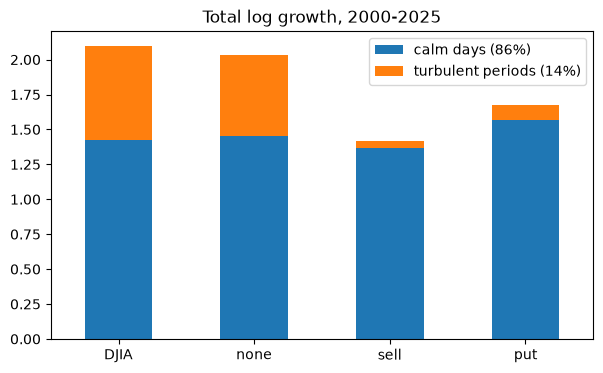

In [16]:
turb = main[(main.strategy == 'ensemble') & (main.rule == 'none')].groupby('date').turbulent.first()
period = turb.astype(int).rolling(11, min_periods=1).max().astype(bool)
growth = pd.DataFrame({name: [np.log1p(r[~period]).sum(), np.log1p(r[period]).sum()] for name, r in
                       {'DJIA': djia.reindex(turb.index), 'none': mean_ret(main, 'none'),
                        'sell': mean_ret(main, 'sell'), 'put': mean_ret(main, 'put')}.items()},
                      index=[f'calm days ({1 - period.mean():.0%})', f'turbulent periods ({period.mean():.0%})'])
growth.T.plot.bar(stacked=True, figsize=(7, 4), title='Total log growth, 2000-2025', rot=0)
growth.round(2)

### 5b. Event study: what happens around a turbulence signal?
Average path from 20 days before to 60 days after turbulence first crosses the threshold (no turbulent day in the 21 days before). Kritzman & Li (2010) found that turbulence persists and returns are weak while it lasts. If the market has already fallen before day 0 and rebounds after, selling at day 0 locks in the loss.

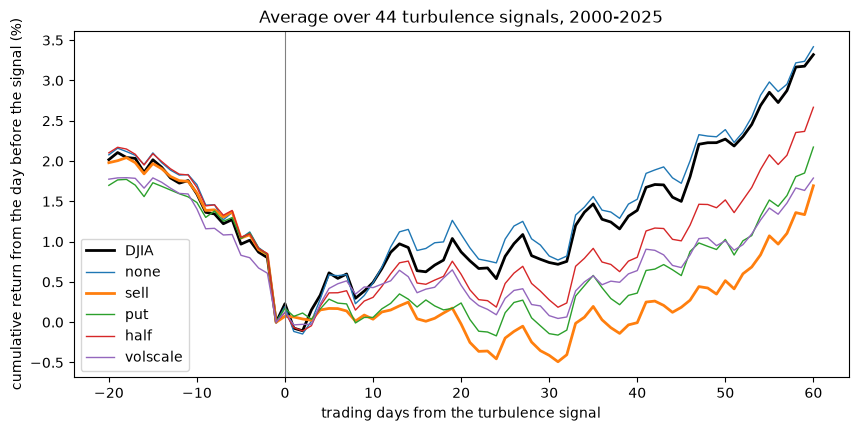

In [17]:
prev = turb.shift(1, fill_value=False).astype(int).rolling(21, min_periods=1).max()
starts = np.where(turb.values & (prev.values == 0))[0]
starts = starts[(starts >= 20) & (starts < len(turb) - 60)]
paths = {'DJIA': djia.reindex(turb.index)} | {rule: mean_ret(main, rule) for rule in ['none', 'sell', 'put']}
paths |= {rule: sweep[sweep.rule == rule].groupby('date').ret.mean().reindex(turb.index) for rule in ['half', 'volscale']}
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, r in paths.items():
    x = np.array([np.cumprod(1 + r.values[i - 20: i + 61]) / np.prod(1 + r.values[i - 20: i]) - 1 for i in starts])
    ax.plot(range(-20, 61), x.mean(0) * 100, label=name, color='black' if name == 'DJIA' else None, lw=2 if name in ['DJIA', 'sell'] else 1)
ax.axvline(0, color='gray', lw=0.8)
ax.set_xlabel('trading days from the turbulence signal')
ax.set_ylabel('cumulative return from the day before the signal (%)')
ax.set_title(f'Average over {len(starts)} turbulence signals, 2000-2025')
ax.legend();

### 5c. Threshold sweep and gentler rules
Each point is one crash rule (ensemble, seeds 0–4). Lines connect the same rule at different turbulence thresholds (the q-quantile of past turbulence); hollow markers are the paper's adaptive threshold.
- **half**: at most 50% in stocks while turbulent.
- **volscale**: every day, at most (usual volatility / last month's volatility) in stocks (Moreira & Muir, 2017).
- **put95**: 5% out-of-the-money puts; **put3m**: 3-month puts.

,Annual return,Annual volatility,Sharpe (rf = 0),Max drawdown
none,8.2%,19.7%,0.50,-56.5%
sell,5.6%,15.9%,0.43,-41.5%
half,6.9%,17.7%,0.47,-52.3%
put,6.7%,17.0%,0.46,-50.3%
put95,7.5%,17.6%,0.50,-52.1%
put3m,3.8%,15.1%,0.32,-50.1%
volscale,4.9%,14.1%,0.41,-40.1%
DJIA,8.7%,18.3%,0.55,-51.8%


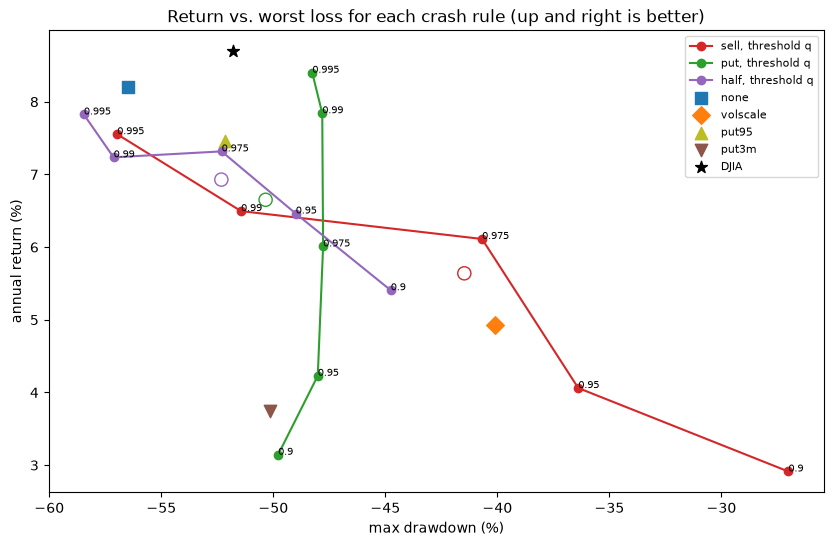

In [18]:
allrules = pd.concat([sweep, main[main.strategy == 'ensemble']])
res = summary(allrules, baselines, by='rule')
fig, ax = plt.subplots(figsize=(10, 6))
for rule, color in [('sell', 'tab:red'), ('put', 'tab:green'), ('half', 'tab:purple')]:
    pts = res[res.index.str.startswith(f'{rule}@q')]
    ax.plot(pts['Max drawdown'] * 100, pts['Annual return'] * 100, 'o-', color=color, label=f'{rule}, threshold q')
    for name, p in pts.iterrows():
        ax.annotate(name.split('@q')[1], (p['Max drawdown'] * 100, p['Annual return'] * 100), fontsize=7)
    ax.scatter(res.loc[rule, 'Max drawdown'] * 100, res.loc[rule, 'Annual return'] * 100, s=90, facecolors='none', edgecolors=color)
for rule, m, color in [('none', 's', 'tab:blue'), ('volscale', 'D', 'tab:orange'), ('put95', '^', 'tab:olive'),
                       ('put3m', 'v', 'tab:brown'), ('DJIA', '*', 'black')]:
    ax.scatter(res.loc[rule, 'Max drawdown'] * 100, res.loc[rule, 'Annual return'] * 100, marker=m, s=80, color=color, label=rule)
ax.set_xlabel('max drawdown (%)')
ax.set_ylabel('annual return (%)')
ax.set_title('Return vs. worst loss for each crash rule (up and right is better)')
ax.legend(fontsize=8);
pretty(res.loc[['none', 'sell', 'half', 'put', 'put95', 'put3m', 'volscale', 'DJIA'], cols])

### 5d. What did the puts cost, and what did they pay?
Premiums paid and payoffs received, as a share of the portfolio, per year (average over seeds). Israelov (2019) found that index puts usually protect *worse* than simply holding less stock, because their price includes a volatility risk premium.

,put_paid,put_payoff,payoff_per_premium
rule,,,
put,142.9%,103.0%,0.72
put3m,163.6%,63.0%,0.39
put95,54.6%,35.8%,0.66


<Axes: title={'center': 'ATM 1-month puts: premium paid and payoff per year (% of portfolio)'}, xlabel='date'>

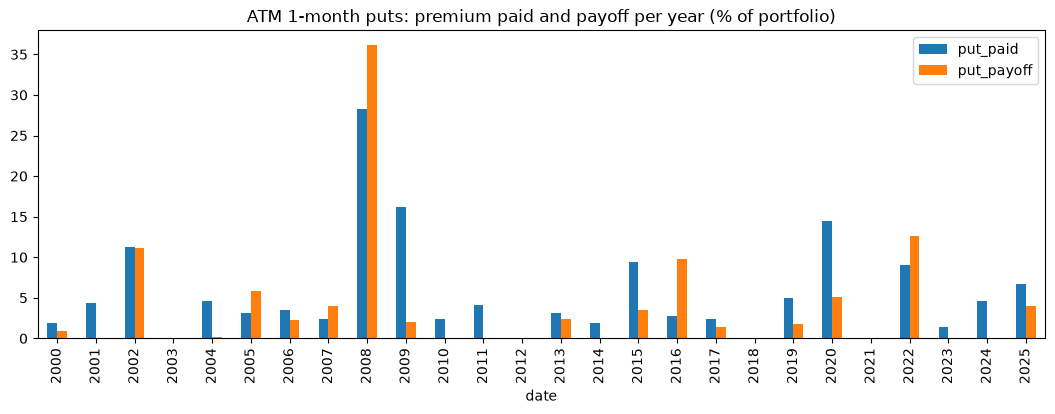

In [19]:
puts = pd.concat([main[(main.strategy == 'ensemble') & (main.rule == 'put')], sweep[sweep.rule.isin(['put95', 'put3m'])]])
flows = puts.groupby(['rule', 'seed', puts.date.dt.year])[['put_paid', 'put_payoff']].sum().groupby(['rule', 'date']).mean()
total = flows.groupby('rule').sum().assign(payoff_per_premium=lambda t: t.put_payoff / t.put_paid)
display(total.style.format({'put_paid': '{:.1%}', 'put_payoff': '{:.1%}', 'payoff_per_premium': '{:.2f}'}))
(flows.loc['put'] * 100).plot.bar(figsize=(13, 4), title='ATM 1-month puts: premium paid and payoff per year (% of portfolio)')

## 6. FTA with 20 seeds
With 5 seeds, FTA's ensemble looked twice as stable (Sharpe std 0.03 vs 0.06), but the F-test gave p = 0.22. With 20 seeds over 2016–2025 the comparison has much more power. Levene's test: are the variances different?

In [20]:
rows = {}
for s in STRATEGIES:
    b, f = sh20.loc[('baseline', s)], sh20.loc[('fta', s)]
    te = {v: np.mean([(g.set_index('date').ret - djia).dropna().std() * np.sqrt(252)
                      for _, g in r20[(r20.variant == v) & (r20.strategy == s)].groupby('seed')]) for v in ['baseline', 'fta']}
    rows[s] = {'Sharpe std, baseline': b.std(), 'Sharpe std, FTA': f.std(), 'Levene p': levene(b, f).pvalue,
               'Tracking error vs DJIA, baseline': te['baseline'], 'Tracking error vs DJIA, FTA': te['fta']}
pd.DataFrame(rows).T.style.format('{:.3f}').format('{:.1%}', subset=['Tracking error vs DJIA, baseline', 'Tracking error vs DJIA, FTA'])

,"Sharpe std, baseline","Sharpe std, FTA",Levene p,"Tracking error vs DJIA, baseline","Tracking error vs DJIA, FTA"
ensemble,0.084,0.072,0.582,8.0%,7.1%
a2c,0.178,0.128,0.140,9.4%,8.2%
ppo,0.105,0.099,0.979,7.1%,6.9%
ddpg,0.117,0.154,0.159,10.6%,9.4%


## Conclusion
**Training: the agents learn to hold the market, not to beat it.**
- They stay almost fully invested (0.2% cash) in about 17 of the 30 stocks, and trade the whole portfolio about 7 times a year: a somewhat concentrated index fund.
- **Learning curves:** in-sample, A2C and DDPG never beat holding the DJIA, at any number of steps. PPO does a bit better with more steps (Sharpe 0.43 → 0.61). On the next quarter, more steps help A2C and PPO, but they stay well below simply holding the DJIA in those quarters. So the base training steps are on the low side, but more training doesn't create an edge.
- **Benchmarks:** the agents beat a random agent (Sharpe 0.37) but not 1/N (0.53) or the DJIA (0.55).

**Choosing an agent is no better than guessing.**
- A good validation quarter says nothing about the next quarter (rank correlations −0.07 to +0.01, none significant), as Lo's ±2.1 standard error for one quarter predicts.
- The picked agent is the best of the three 35% of the time; guessing gives 33%. A random pick (0.51) and an equal mix (0.53) do as well as the ensemble (0.50), and always using PPO does better (0.55). The hindsight oracle (1.15) shows what a good selector *could* add, but 3 months of validation can't find it.

**How sure are we?**
- **Seed noise is small next to market noise.** With 20 seeds, the ensemble's 2016–2025 Sharpe varies by 0.08 from seed to seed, while the market uncertainty of that Sharpe is about 0.31. After about 5 seeds, more seeds hardly change the performance answers; more years would.
- Over 25 years every Sharpe ratio has a 95% interval of about ±0.37, and **no strategy is significantly different from the DJIA**. The paper's sell rule is 0.10 below it (interval −0.28 to +0.09). The paper's 1.30 is far outside anything our runs produce.

**Robustness.**
- Training on the last 5 years only gives the same results (better in 41–51% of quarters, all p > 0.4). Old data isn't what holds the agents back.
- Fees matter only a little: Sharpe 0.53 without fees, 0.50 at the paper's 0.1%, 0.46 at 0.2%.

**The crash rule.**
- Almost the whole gap to the DJIA comes from the 14% of days around turbulence: there the sell rule gains 0.05 in log growth against 0.67 for the DJIA.
- **Event study:** the DJIA has already fallen about 2% in the 20 days before a signal, then gains about 3.3% in the next 60 days. Selling at the signal locks in the fall and misses half the rebound.
- **Almost no rule beats doing nothing on return.** Only puts at the 99.5th-percentile threshold edge ahead (8.4% against 8.2% a year), a gap within noise. A higher threshold moves every rule towards `none`; a lower one cuts drawdowns but costs a lot of return (selling at q = 0.90: −27% drawdown but 2.9% a year). Holding half and volatility scaling are no better than the sell rule's trade-off curve.
- **Puts are expensive insurance.** They paid back 72 cents per dollar of premium (1-month at the money), 66 cents (5% out of the money) and 39 cents (3-month). The best variant, 5% out-of-the-money puts, matches doing nothing on Sharpe ratio (0.50) with a smaller drawdown (−52% against −57%). This fits Israelov (2019). Our puts are priced at VIX, which overstates their cost somewhat.

**FTA with 20 seeds.** The narrower band seen with 5 seeds was chance. With 20 seeds the ensemble's Sharpe spread is 0.084 (baseline) against 0.072 (FTA), p = 0.58, and for DDPG it's now *wider* with FTA. The one consistent pattern: FTA agents track the DJIA a little more closely (lower tracking error for all four strategies, e.g. 8.0% → 7.1% for the ensemble), with the same average Sharpe ratio.